# Test the research supervisor

شغّلي الخلية الأولى لإنشاء كائن المشرف، ثم الخلية الثانية لمشاهدة التفويض والإجابة. يتصل هذا الاختبار بـOllama وarXiv.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from langchain_ollama import ChatOllama

from src.paper_research_supervisor import PaperResearchSupervisor
from src.paper_search_agent import PaperSearchAgent
from src.paper_summary_agent import PaperSummaryAgent
from src.paper_tools import PaperTools

model = ChatOllama(model="llama3.2:latest", temperature=0, num_ctx=8192)
search_agent = PaperSearchAgent(model, PaperTools())
summary_agent = PaperSummaryAgent(model)
supervisor = PaperResearchSupervisor(model, search_agent, summary_agent)

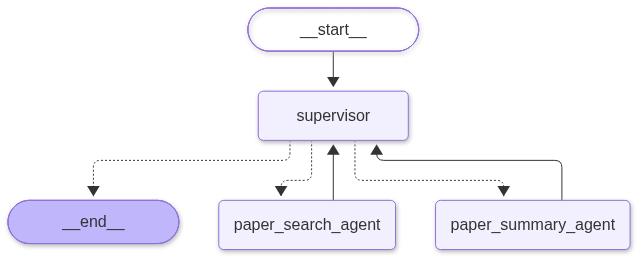

In [4]:


from IPython.display import Image, display

display(Image(supervisor.graph.get_graph().draw_mermaid_png()))

In [ ]:
request = "Find one arXiv paper about large language models and summarize its abstract."
result = supervisor.invoke(request)

handoffs = [
    call["name"]
    for message in result["messages"]
    for call in getattr(message, "tool_calls", [])
    if call["name"].startswith("transfer_to_")
]
print("Handoffs:", handoffs)
expected_handoffs = ["transfer_to_paper_search_agent", "transfer_to_paper_summary_agent"]
search_results = [
    message for message in result["messages"]
    if message.type == "tool" and message.name == "search_papers"
    and message.status == "success" and message.content not in ("", "[]")
]
if handoffs == expected_handoffs and search_results:
    print(result["messages"][-1].content)
else:
    print("Test incomplete: expected search results followed by the summary handoff.")